In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
inputs = [[0, 0], [0, 1], [1, 0], [1, 1]]
answers = [0, 0, 0, 1]


weights = [0.0, 0.0]
bias = 0.0
learning_rate = 0.1

In [3]:
for epoch in range(1, 11):
    mistakes = 0
    
    for x, real in zip(inputs, answers):
        total = bias + x[0] * weights[0] +x[1] * weights[1]
        guess = 1 if total > 0 else 0
        
        error = real - guess
        if error !=0:
            mistakes = mistakes + 1
            weights[0] = weights[0] + learning_rate * error * x[0]
            weights[1] = weights[0] + learning_rate * error * x[1]
            bias = bias + learning_rate * error
            
    print(f"Epoch {epoch}: mistakes = {mistakes}, weights = {[round(w, 2) for w in weights]}, bias = {round(bias, 2)}")
    if mistakes ==0:
            print("No more mistakes. The perceptron has learned!")
            break

Epoch 1: mistakes = 1, weights = [0.1, 0.2], bias = 0.1
Epoch 2: mistakes = 3, weights = [0.2, 0.3], bias = 0.0
Epoch 3: mistakes = 3, weights = [0.2, 0.3], bias = -0.1
Epoch 4: mistakes = 1, weights = [0.2, 0.1], bias = -0.2
Epoch 5: mistakes = 0, weights = [0.2, 0.1], bias = -0.2
No more mistakes. The perceptron has learned!


In [4]:
print("A B | answer")
for x in inputs:
    total = bias + x[0] * weights[0] + x[1] * weights[1]
    print(x[0], " ", x[1], " |", 1 if total > 0 else 0)

A B | answer
0   0  | 0
0   1  | 0
1   0  | 0
1   1  | 1


In [14]:
#np.random.seed(42)
#n = 60


#students = pd.DataFrame({
 #   "hours_studied": np.random.uniform(0, 10, n).round(1),
 #   "attendance_pct": np.random.uniform(40, 100, n).round(0),
#})

#score = students["hours_studied"] * 6 + students["attendance_pct"] * 0.5 + np.random.normal(0, 4, n)
#students["passed"] = (score>60).astype(int)

#students.head()

students = pd.read_csv("perc_student.csv")
students.head()


,hours_studied,attendance_pct,passed
0,3.7,63.0,0
1,9.5,56.0,1
2,7.3,90.0,1
3,6.0,61.0,1
4,1.6,57.0,0


In [15]:
print(students["passed"].value_counts())

passed
0    33
1    27
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

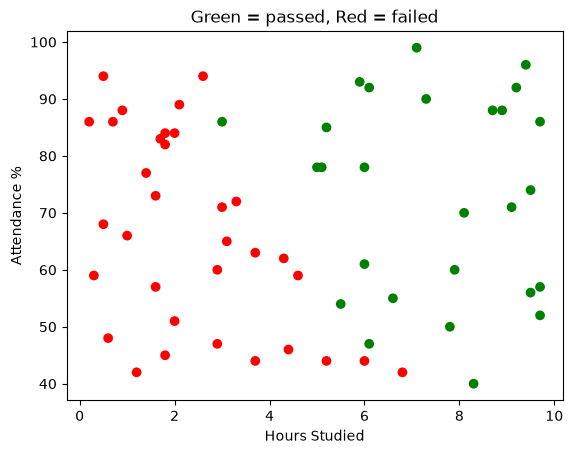

In [16]:
colors = students["passed"].map({0: "red", 1: "green"})
plt.scatter(students["hours_studied"], students["attendance_pct"], c=colors)
plt.xlabel("Hours Studied")
plt.ylabel("Attendance %")
plt.title("Green = passed, Red = failed")
plt.show


Step 1: Faeture, label and split

In [23]:
X = students[["hours_studied", "attendance_pct"]]
y = students["passed"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training students:", len(X_train))
print("Testing students:", len(X_test))


Training students: 48
Testing students: 12


Step 2: Scaling the Data

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
model = Perceptron(random_state=42)
model.fit(X_train_scaled, y_train)


print("Learned weights:", model.coef_.round(2))
print("Learned bias:   ", model.intercept_.round(2))


Learned weights: [[4.69 3.04]]
Learned bias:    [0.]


In [27]:
predictions = model.predict(X_test_scaled)
print("Accuracy:", round(accuracy_score(y_test, predictions), 2))

Accuracy: 0.92


In [28]:
new_student = pd.DataFrame({"hours_studied": [7], "attendance_pct": [80]})
new_scaled = scaler.transform(new_student)

result = model.predict(new_scaled)[0]
print("Prediction:", "PASS" if result == 1 else "FAIL")

Prediction: PASS


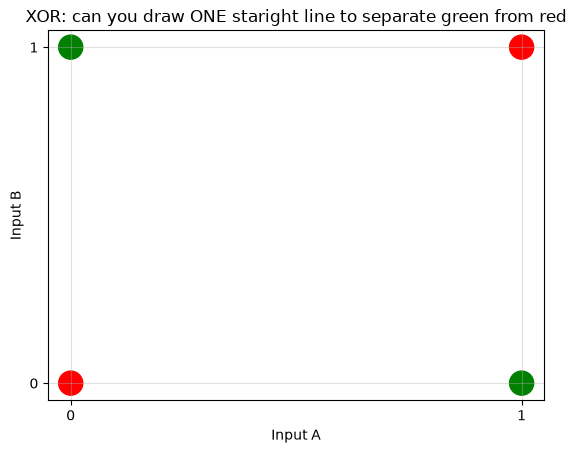

In [29]:
xor_inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
xor_answers = np.array([0, 1, 1, 0])

colors = ["green" if a ==1 else "red" for a in xor_answers]
plt.scatter(xor_inputs[:, 0], xor_inputs[:, 1], c=colors, s=300)
plt.xlabel("Input A")
plt.ylabel("Input B")
plt.title("XOR: can you draw ONE staright line to separate green from red")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(alpha=0.4)
plt.show()

In [30]:
xor_model = Perceptron(max_iter=1000, random_state=42)
xor_model.fit(xor_inputs, xor_answers)


xor_predictions = xor_model.predict(xor_inputs)
print("Real answers:", xor_answers)
print("Perceptron:  ", xor_predictions)
print("Accuracy:", accuracy_score(xor_answers, xor_predictions))

Real answers: [0 1 1 0]
Perceptron:   [0 0 0 0]
Accuracy: 0.5
